# Exercício 3 — Robustez, Resiliência e Hierarquia em Redes Complexas
UFPR · Biologia Computacional

Análise das redes reais Facebook e Western US Power Grid com **python-igraph**.
Execute as células na ordem apresentada. As tabelas e figuras serão salvas em
`output/` para apoiar a redação posterior do relatório de 3 a 5 páginas.
O relatório final e a identificação do grupo serão preparados posteriormente.

Referências metodológicas: `professor/EaD3_Script1.R` e `professor/EaD3_Script2.R`.
Usamos os datasets reais; grafos pequenos aparecem somente nos testes.

In [1]:
from pathlib import Path
import sys
import os
import json
from importlib.metadata import version

# Funciona ao abrir o notebook na raiz ou na pasta notebooks.
RAIZ = Path.cwd().resolve()
if not (RAIZ / 'src').is_dir():
    RAIZ = RAIZ.parent
if not (RAIZ / 'professor' / 'EaD3_Script2.R').is_file():
    raise FileNotFoundError('Abra o notebook na raiz do exercício ou em notebooks/.')
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
os.environ.setdefault('MPLCONFIGDIR', str(RAIZ / '.cache' / 'matplotlib'))

import pandas as pd
from IPython.display import display, Markdown, Image
from src.carregar_redes import carregar_redes
from src.metricas import caracterizar_rede, analisar_kcore
from src.simulacao import simular_resiliencia
from src.visualizacao import plotar_rede, plotar_resiliencia, exportar_resultados

RESULTADOS = RAIZ / 'output' / 'resultados'
GRAFICOS = RAIZ / 'output' / 'graficos'
for pasta in (RESULTADOS, GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)
N_REMOCOES, N_REPETICOES, SEMENTE = 10, 5, 123
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 6)

def slug(nome):
    return nome.lower().replace(' ', '_')

versoes = {p: version(p) for p in ['igraph', 'pandas', 'matplotlib', 'nbclient', 'pytest']}
(RESULTADOS / 'parametros.json').write_text(json.dumps({
    'n_remover': N_REMOCOES, 'n_rep': N_REPETICOES, 'semente': SEMENTE,
    'python': sys.version.split()[0], 'versoes': versoes,
    'desempate': 'ID original em ordem lexicográfica',
    'aleatoriedade': 'random.Random(123); sample sem reposição; nova rede em cada repetição',
    'apl': 'pares alcançáveis da rede inteira; directed=False, unconn=True',
    'apl_lcc': 'pares da maior componente conectada',
}, indent=2, ensure_ascii=False), encoding='utf-8')
display(versoes)

{'igraph': '0.11.9',
 'pandas': '2.2.3',
 'matplotlib': '3.9.4',
 'nbclient': '0.10.2',
 'pytest': '8.4.2'}

## 1. Importação, limpeza e caracterização

As fontes são [SNAP — Facebook](https://snap.stanford.edu/data/ego-Facebook.html)
e [Network Repository — inf-power](https://networkrepository.com/inf-power.php).
O carregador usa os arquivos originais, preserva os identificadores em `name`
e remove loops e duplicatas. As duas redes são não direcionadas segundo as fontes.
O diâmetro é calculado na LCC quando houver desconexão; o número de componentes
permite identificar essa situação. A transitividade é global, sem confundi-la com
 a média dos coeficientes locais de agrupamento.

In [2]:
redes = carregar_redes(RAIZ / 'data', baixar=True)
caracterizacao = pd.DataFrame([
    {'rede': nome, **caracterizar_rede(g)} for nome, g in redes.items()
])
caracterizacao.to_csv(RESULTADOS / 'caracterizacao.csv', index=False)
fontes = json.loads((RAIZ / 'data' / 'fontes.json').read_text(encoding='utf-8'))
display(caracterizacao)
display(fontes)

,rede,n_vertices,n_arestas,direcionada,densidade,diametro,transitividade_global,n_componentes,lcc
0,Facebook,4039,88234,False,0.01082,8,0.519174,1,4039
1,Power Grid,4941,6594,False,0.00054,46,0.103153,1,4941


{'Facebook': {'arquivo': 'facebook_combined.txt.gz',
  'sha256': '125e84db872eeba443d270c70315c256b0af43a502fcfe51f50621166ad035d7',
  'url': 'https://snap.stanford.edu/data/facebook_combined.txt.gz'},
 'Power Grid': {'arquivo': 'inf-power.zip',
  'sha256': 'ea5aac207591d6dd863f470641a617aa87059a923282bea9d969335a9904f606',
  'url': 'https://nrvis.com/download/data/inf/inf-power.zip'}}

## 2. Decomposição K-core

Como no Script 1, calculamos coreness e betweenness exatas na rede original
simplificada. O núcleo máximo contém os vértices com coreness igual a k-max.
Seus cinco maiores graus são medidos **dentro do subgrafo do núcleo**; o grau
relativo é o grau interno dividido por `n-1` desse subgrafo. Empates usam a ordem
lexicográfica dos IDs originais. Grau elevado e pertencimento ao núcleo são
propriedades distintas.

As métricas estáticas são armazenadas nos atributos dos vértices e reutilizadas
na simulação e nas figuras, sem novo cálculo de betweenness. Também salvamos
as métricas de todos os nós em CSV para consulta posterior.

In [3]:
nucleos = {}
resumos, maiores_graus, metricas_nos = [], [], []
for nome, g in redes.items():
    resultado = analisar_kcore(g)
    nucleos[nome] = resultado
    resumos.append({'rede': nome, **{
        k: resultado[k] for k in ['kmax', 'n_kmax', 'densidade_kmax', 'assortatividade']
    }})
    maiores_graus.append(resultado['top5'].assign(rede=nome))
    metricas_nos.append(pd.DataFrame({
        'rede': nome, 'id_original': g.vs['name'], 'grau': g.degree(),
        'coreness': g.vs['coreness'], 'betweenness': g.vs['betweenness'],
        'no_kmax_original': [c == resultado['kmax'] for c in g.vs['coreness']],
    }))
resumo_nucleos = pd.DataFrame(resumos)
top5 = pd.concat(maiores_graus, ignore_index=True)
metricas_nos = pd.concat(metricas_nos, ignore_index=True)
resumo_nucleos.to_csv(RESULTADOS / 'nucleos.csv', index=False)
top5.to_csv(RESULTADOS / 'top5_nucleo.csv', index=False)
metricas_nos.to_csv(RESULTADOS / 'metricas_nos.csv', index=False)
display(resumo_nucleos)
display(top5)

,rede,kmax,n_kmax,densidade_kmax,assortatividade
0,Facebook,115,158,0.898492,0.063577
1,Power Grid,5,12,0.545455,0.003457


,id_original,grau_interno,grau_relativo,rede
0,1912,157,1.000000,Facebook
1,2206,157,1.000000,Facebook
2,2340,157,1.000000,Facebook
3,2507,157,1.000000,Facebook
4,2088,156,0.993631,Facebook
5,4353,7,0.636364,Power Grid
6,4382,7,0.636364,Power Grid
7,4403,7,0.636364,Power Grid
8,4333,6,0.545455,Power Grid
9,4385,6,0.545455,Power Grid


## 3. Simulação de ataques e falhas

Seguimos o Script 2: dez alvos definidos pela **betweenness inicial**, sem atualizar
o ranking durante o ataque; cinco falhas aleatórias, cada uma reiniciada a partir
da rede original; semente 123. Incluímos o passo zero em todas as trajetórias.
O sorteador Python não reproduz a sequência exata de `sample()` do R, mas mantém
os mesmos parâmetros, o sorteio sem reposição e a metodologia.

`apl` exclui pares inalcançáveis da rede inteira (`unconn=True`), como no professor.
`apl_lcc` é medido exclusivamente na LCC. As duas definições são armazenadas e
plotadas separadamente. O coreness é recalculado após cada remoção. Os IDs
originais são usados para remover vértices, evitando a renumeração do igraph.
Os cálculos de caminhos são exatos e podem levar alguns minutos.

In [4]:
todos_detalhes, todas_medias, todos_alvos = [], [], []
for nome, g in redes.items():
    print(f'Simulando {nome}...', flush=True)
    detalhes_rede, medias_rede, alvos_rede = simular_resiliencia(
        g, nome, n_remover=N_REMOCOES, n_rep=N_REPETICOES, semente=SEMENTE
    )
    todos_detalhes.append(detalhes_rede)
    todas_medias.append(medias_rede)
    todos_alvos.append(alvos_rede)
detalhes = pd.concat(todos_detalhes, ignore_index=True)
medias = pd.concat(todas_medias, ignore_index=True)
alvos = pd.concat(todos_alvos, ignore_index=True)
exportar_resultados(detalhes, medias, alvos, RESULTADOS)
display(alvos)
display(medias[medias['passo'].isin([0, N_REMOCOES])])

Simulando Facebook...


Simulando Power Grid...


,rede,ordem,id_original,betweenness,coreness,no_kmax_original
0,Facebook,1,107,3.916560e+06,70,False
1,Facebook,2,1684,2.753287e+06,43,False
2,Facebook,3,3437,1.924506e+06,22,False
3,Facebook,4,1912,1.868918e+06,115,True
4,Facebook,5,1085,1.214578e+06,22,False
5,Facebook,6,0,1.192496e+06,21,False
6,Facebook,7,698,9.400242e+05,17,False
7,Facebook,8,567,7.849969e+05,31,False
8,Facebook,9,58,6.875950e+05,6,False
9,Facebook,10,428,5.241641e+05,31,False


,rede,estrategia,passo,n_vertices,lcc,lcc_frac,apl,apl_lcc,kmax,n_kmax
0,Facebook,Ataque direcionado,0,4039.0,4039.0,1.000000,3.692507,3.692507,115.0,158.0
10,Facebook,Ataque direcionado,10,4029.0,3220.0,0.797227,4.842216,4.889043,114.0,157.0
11,Facebook,Falha aleatória,0,4039.0,4039.0,1.000000,3.692507,3.692507,115.0,158.0
21,Facebook,Falha aleatória,10,4029.0,4029.0,0.997524,3.693146,3.693146,115.0,158.0
22,Power Grid,Ataque direcionado,0,4941.0,4941.0,1.000000,18.989185,18.989185,5.0,12.0
32,Power Grid,Ataque direcionado,10,4931.0,4930.0,0.997774,24.593551,24.593551,5.0,12.0
33,Power Grid,Falha aleatória,0,4941.0,4941.0,1.000000,18.989185,18.989185,5.0,12.0
43,Power Grid,Falha aleatória,10,4931.0,4928.0,0.997369,19.053611,19.053612,5.0,12.0


In [5]:
# Verificações sobre os resultados reais das duas redes.
assert len(detalhes) == len(redes) * (N_REMOCOES + 1) * (N_REPETICOES + 1)
assert len(medias) == len(redes) * (N_REMOCOES + 1) * 2
assert len(alvos) == len(redes) * N_REMOCOES
for (nome, estrategia, repeticao), grupo in detalhes.groupby(['rede', 'estrategia', 'repeticao']):
    grupo = grupo.sort_values('passo')
    n_original = redes[nome].vcount()
    assert grupo['passo'].tolist() == list(range(N_REMOCOES + 1))
    assert grupo['n_vertices'].tolist() == [n_original - i for i in range(N_REMOCOES + 1)]
    assert (grupo['lcc'].diff().dropna() <= 0).all()
    assert (grupo['kmax'].diff().dropna() <= 0).all()
    assert grupo.loc[grupo['passo'] > 0, 'id_removido'].nunique() == N_REMOCOES
    assert set(grupo['id_removido'].dropna()).issubset(set(redes[nome].vs['name']))
    assert (grupo['lcc_frac'] - grupo['lcc'] / n_original).abs().max() < 1e-12
print(f'Validados: {len(detalhes)} registros, {len(medias)} médias e {len(alvos)} alvos.')

Validados: 132 registros, 44 médias e 20 alvos.


## 4. Visualizações

O layout de força segue a referência do professor. Cor indica coreness, área
dos nós é escalada pela betweenness e contorno destaca o núcleo máximo.
Todos os nós e arestas são mantidos, com transparência e sem rótulos em massa.

As curvas comparam o ataque com a média das cinco falhas. Os gráficos equivalentes
usam escalas comuns entre redes. Nos indicadores de núcleo, um segundo painel
amplia o eixo Y de cada rede para revelar pequenas variações; as legendas
informam os valores inicial e final. Os comparativos de k-max e tamanho do núcleo
são normalizados pelos respectivos valores iniciais; os dois caminhos médios
permanecem em figuras distintas.

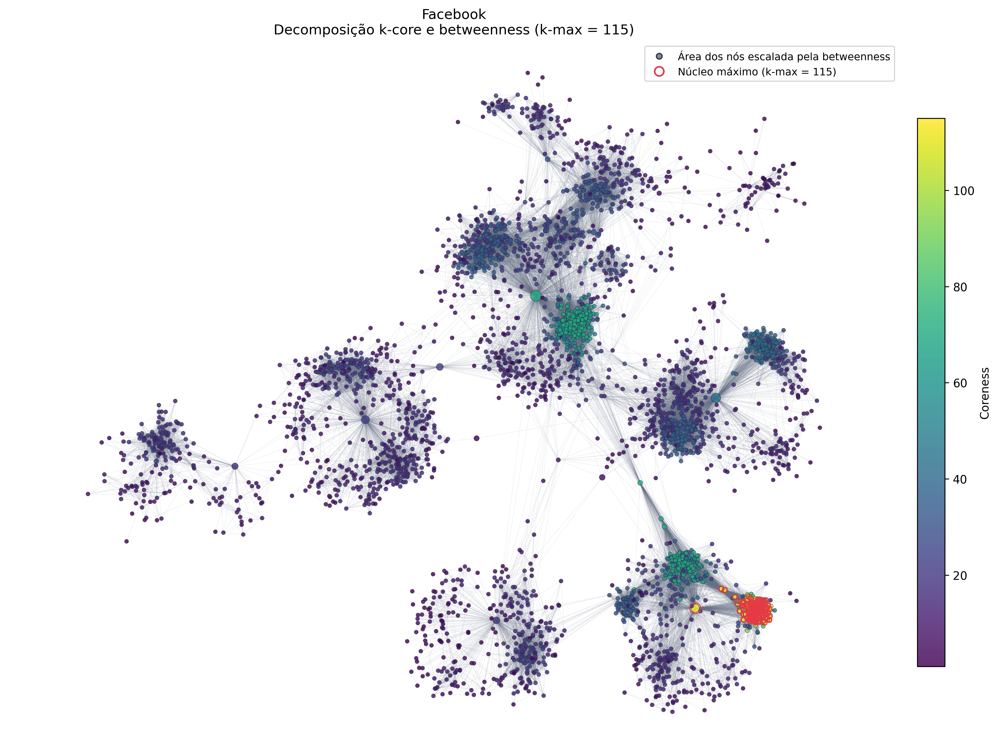

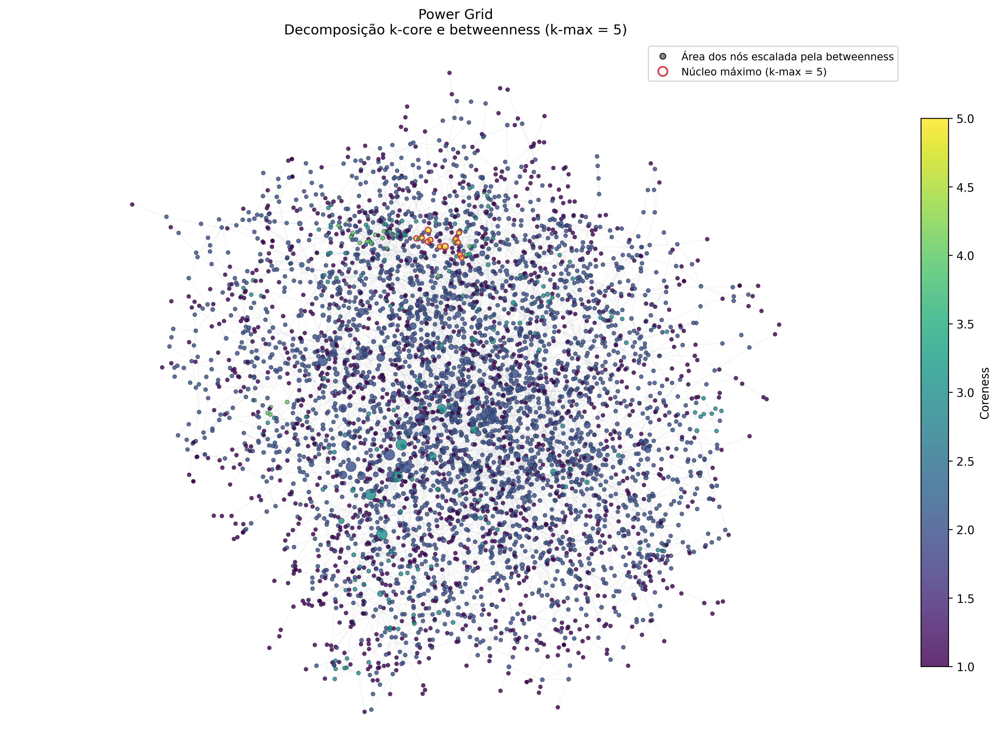

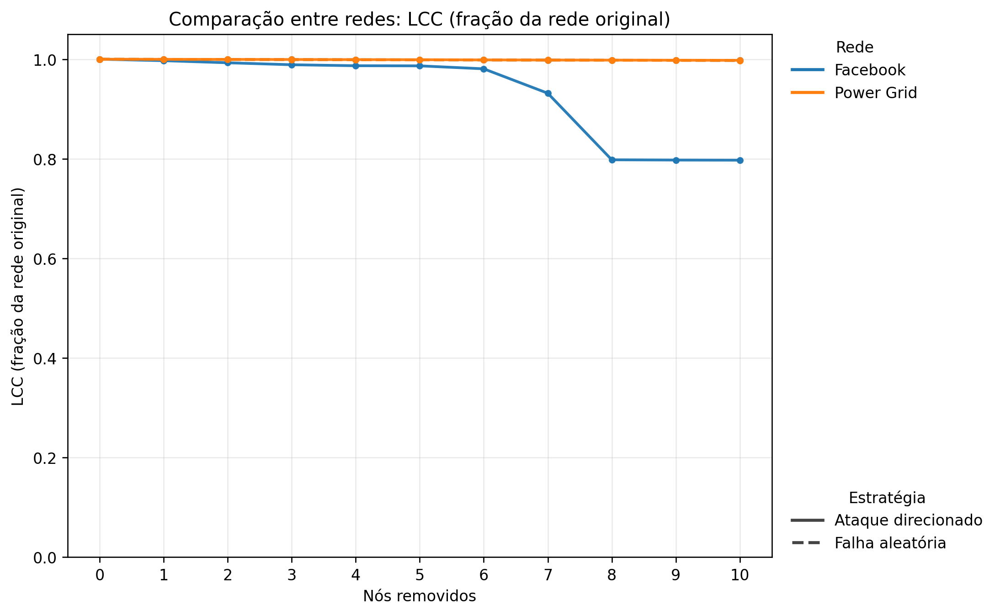

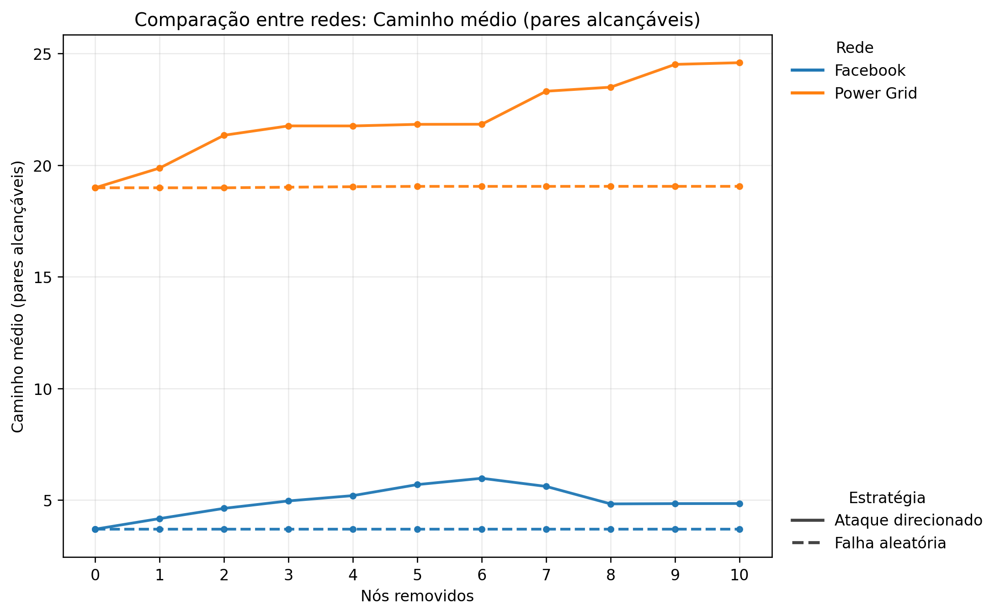

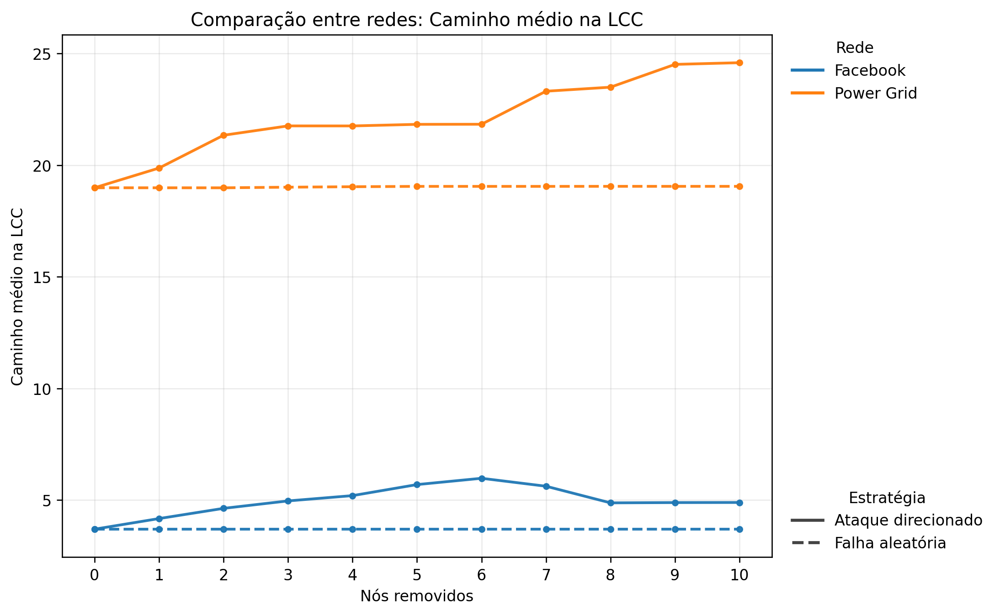

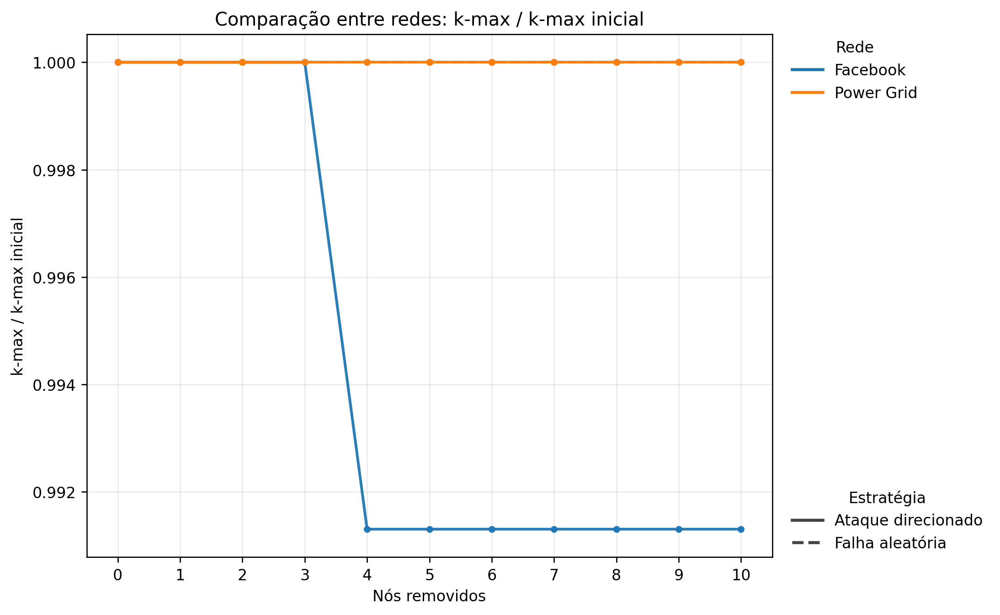

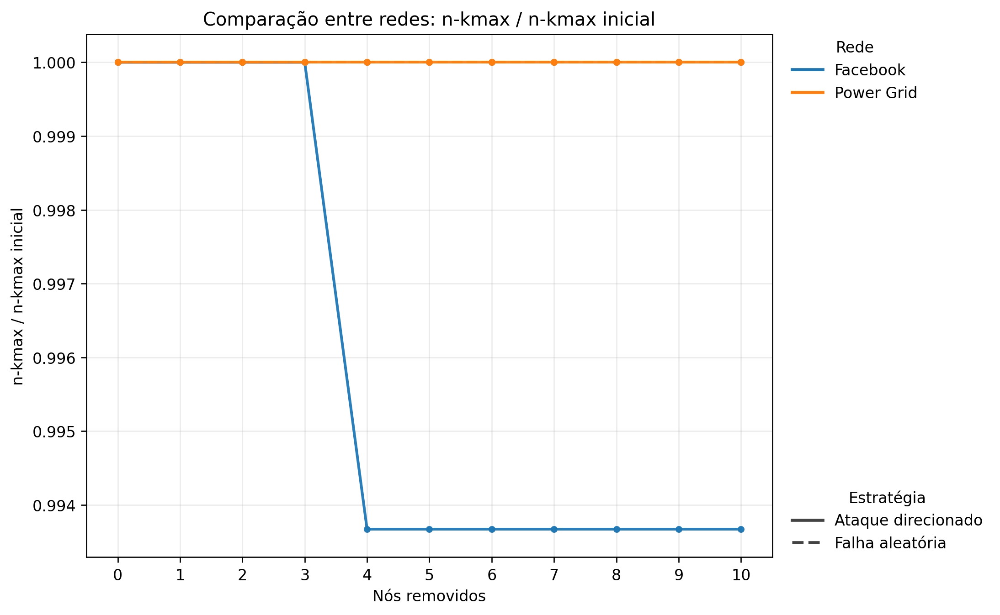

17 figuras PNG salvas em output/graficos/.


In [6]:
figuras_rede = []
for nome, g in redes.items():
    arquivo = plotar_rede(g, nome, GRAFICOS / f'{slug(nome)}_kcore.png', semente=SEMENTE)
    figuras_rede.append(arquivo)
    display(Image(filename=str(arquivo), width=800))
figuras_resiliencia = plotar_resiliencia(medias, GRAFICOS)
for arquivo in figuras_resiliencia:
    if arquivo.name.startswith('comparativo_'):
        display(Image(filename=str(arquivo), width=800))
print(f'{len(figuras_rede) + len(figuras_resiliencia)} figuras PNG salvas em output/graficos/.')

### Revisão das curvas de K-core

Os CSVs foram conferidos reconstruindo os grafos após as remoções e validando
os núcleos também por remoção iterativa dos vértices com grau menor que k.
As curvas quase constantes têm explicação estrutural:

| Facebook | k-max | Nós no núcleo máximo |
| --- | ---: | ---: |
| Ataque, passos 0 a 3 | 115 | 158 |
| Ataque, passos 4 a 10 | 114 | 157 |
| Falhas, todas as cinco repetições e todos os passos | 115 | 158 |

O nó `1912`, removido no passo 4, é o único dos dez alvos que pertence ao núcleo
original. Dentro desse núcleo ele se ligava aos outros 157 vértices. Sua remoção
reduz o grau interno mínimo de 115 para 114; os 157 sobreviventes formam o novo
núcleo máximo. Nas falhas aleatórias, nenhum dos nós sorteados pertenceu ao
núcleo original, preservando suas arestas internas.

A queda é pequena e estava comprimida pela escala comum com o Power Grid.
O painel à direita dos gráficos abaixo amplia o eixo Y; a alteração é de
**uma unidade**, sem mudança nos dados:

![Facebook: k-max, escala comum e detalhe](../output/graficos/facebook_kmax.png)

![Facebook: tamanho do núcleo, escala comum e detalhe](../output/graficos/facebook_n_kmax.png)

Ao fim do ataque, esses 157 nós continuam na LCC de 3.220 vértices. O núcleo
denso permanece quase preservado enquanto outras partes se separam, explicando
a redução de 20,28% da LCC. K-max e LCC medem aspectos diferentes da estrutura.
No Power Grid, nenhuma remoção atingiu o núcleo original: k-max 5 e 12 membros
se mantiveram em todas as trajetórias. A constância se refere a esses indicadores;
ela não demonstra que o coreness de todos os outros nós permaneceu inalterado.

A revisão completa está em `output/resultados/revisao_dados.md`.


## 5. Comparação e diagnóstico estrutural

A tabela abaixo compara o estado inicial com o passo dez e quantifica os alvos
no núcleo original. A redução proporcional da LCC usa como denominador a LCC
inicial. `fora_lcc_final` mede quantos nós remanescentes estão fora da LCC;
na falha aleatória é a média entre repetições. A perda de nós da LCC pode refletir
tanto remoções diretas quanto fragmentação dos nós remanescentes.

Interpretamos o tamanho do núcleo junto com k-max: um núcleo maior após queda
de k-max não significa melhora da resiliência. Uma queda do caminho médio pode
ocorrer quando partes distantes deixam de ser alcançáveis. Este experimento
avalia **conectividade topológica**; não modela fluxo elétrico, sobrecarga ou uma
falha elétrica real. Dez remoções são uma pequena fração destas redes e não
sustentam, por si só, conclusões gerais sobre toda a curva de robustez.

In [7]:
linhas = []
for (nome, estrategia), grupo in medias.groupby(['rede', 'estrategia']):
    inicial = grupo.loc[grupo['passo'] == 0].iloc[0]
    final = grupo.loc[grupo['passo'] == N_REMOCOES].iloc[0]
    final_detalhes = detalhes[(detalhes['rede'] == nome) &
                              (detalhes['estrategia'] == estrategia) &
                              (detalhes['passo'] == N_REMOCOES)]
    linhas.append({
        'rede': nome, 'estrategia': estrategia,
        'lcc_frac_inicial': inicial['lcc_frac'], 'lcc_frac_final': final['lcc_frac'],
        'reducao_proporcional_lcc': 1 - final['lcc_frac'] / inicial['lcc_frac'],
        'fora_lcc_final': (final_detalhes['n_vertices'] - final_detalhes['lcc']).mean(),
        'apl_inicial': inicial['apl'], 'apl_final': final['apl'],
        'apl_lcc_inicial': inicial['apl_lcc'], 'apl_lcc_final': final['apl_lcc'],
        'kmax_inicial': inicial['kmax'], 'kmax_final': final['kmax'],
        'n_kmax_inicial': inicial['n_kmax'], 'n_kmax_final': final['n_kmax'],
    })
diagnostico = pd.DataFrame(linhas)
alvos_no_nucleo = alvos.groupby('rede', as_index=False)['no_kmax_original'].sum().rename(
    columns={'no_kmax_original': 'alvos_no_kmax_original'}
)
comparacao = caracterizacao.merge(resumo_nucleos, on='rede').merge(alvos_no_nucleo, on='rede')
comparacao.to_csv(RESULTADOS / 'comparacao_estrutural.csv', index=False)
diagnostico.to_csv(RESULTADOS / 'diagnostico_resiliencia.csv', index=False)
display(comparacao)
display(diagnostico)

,rede,n_vertices,n_arestas,direcionada,densidade,diametro,transitividade_global,n_componentes,lcc,kmax,n_kmax,densidade_kmax,assortatividade,alvos_no_kmax_original
0,Facebook,4039,88234,False,0.01082,8,0.519174,1,4039,115,158,0.898492,0.063577,1
1,Power Grid,4941,6594,False,0.00054,46,0.103153,1,4941,5,12,0.545455,0.003457,0


,rede,estrategia,lcc_frac_inicial,lcc_frac_final,reducao_proporcional_lcc,fora_lcc_final,apl_inicial,apl_final,apl_lcc_inicial,apl_lcc_final,kmax_inicial,kmax_final,n_kmax_inicial,n_kmax_final
0,Facebook,Ataque direcionado,1.0,0.797227,0.202773,809.0,3.692507,4.842216,3.692507,4.889043,115.0,114.0,158.0,157.0
1,Facebook,Falha aleatória,1.0,0.997524,0.002476,0.0,3.692507,3.693146,3.692507,3.693146,115.0,115.0,158.0,158.0
2,Power Grid,Ataque direcionado,1.0,0.997774,0.002226,1.0,18.989185,24.593551,18.989185,24.593551,5.0,5.0,12.0,12.0
3,Power Grid,Falha aleatória,1.0,0.997369,0.002631,3.0,18.989185,19.053611,18.989185,19.053612,5.0,5.0,12.0,12.0


In [8]:
# Interpretações derivadas somente dos valores calculados.
maior_k = resumo_nucleos.loc[resumo_nucleos['kmax'].idxmax()]
mais_denso = resumo_nucleos.loc[resumo_nucleos['densidade_kmax'].idxmax()]
textos = [
    f"**Maior k-max:** {maior_k['rede']} ({int(maior_k['kmax'])}).",
    f"**Núcleo mais denso:** {mais_denso['rede']} ({mais_denso['densidade_kmax']:.6f}).",
]
for nome in redes:
    estrutural = comparacao[comparacao['rede'] == nome].iloc[0]
    por_estrategia = diagnostico[diagnostico['rede'] == nome].set_index('estrategia')
    ataque = por_estrategia.loc['Ataque direcionado']
    falha = por_estrategia.loc['Falha aleatória']
    diferenca = ataque['reducao_proporcional_lcc'] - falha['reducao_proporcional_lcc']
    observacao = ('O ataque causou maior perda proporcional da LCC.' if diferenca > 1e-12 else
                  'As falhas causaram maior perda proporcional da LCC.' if diferenca < -1e-12 else
                  'As duas estratégias tiveram a mesma perda proporcional da LCC.')
    textos.append(
        f"**{nome}:** assortatividade {estrutural['assortatividade']:.6f}; "
        f"{int(estrutural['alvos_no_kmax_original'])}/{N_REMOCOES} alvos no núcleo original. "
        f"Redução da LCC: ataque {ataque['reducao_proporcional_lcc']:.2%}; "
        f"falha média {falha['reducao_proporcional_lcc']:.2%}. {observacao} "
        f"Após o ataque, {ataque['fora_lcc_final']:.0f} nós remanescentes ficaram fora da LCC "
        f"(falha média: {falha['fora_lcc_final']:.1f}). "
        f"APL no ataque: {ataque['apl_inicial']:.3f} → {ataque['apl_final']:.3f}; "
        f"APL da LCC: {ataque['apl_lcc_inicial']:.3f} → {ataque['apl_lcc_final']:.3f}."
    )
pior = diagnostico.loc[diagnostico['reducao_proporcional_lcc'].idxmax()]
textos.append(f"**Maior redução observada:** {pior['rede']}, {pior['estrategia']} "
              f"({pior['reducao_proporcional_lcc']:.2%}).")
textos.append('As diferenças observadas permitem discutir robustez neste recorte de dez remoções; '
              'cinco repetições não esgotam a variabilidade das falhas aleatórias.')
display(Markdown('\n\n'.join(textos)))
display(pd.DataFrame({'arquivo': [p.relative_to(RAIZ).as_posix()
                                 for p in sorted(RESULTADOS.glob('*'))]}))

**Maior k-max:** Facebook (115).

**Núcleo mais denso:** Facebook (0.898492).

**Facebook:** assortatividade 0.063577; 1/10 alvos no núcleo original. Redução da LCC: ataque 20.28%; falha média 0.25%. O ataque causou maior perda proporcional da LCC. Após o ataque, 809 nós remanescentes ficaram fora da LCC (falha média: 0.0). APL no ataque: 3.693 → 4.842; APL da LCC: 3.693 → 4.889.

**Power Grid:** assortatividade 0.003457; 0/10 alvos no núcleo original. Redução da LCC: ataque 0.22%; falha média 0.26%. As falhas causaram maior perda proporcional da LCC. Após o ataque, 1 nós remanescentes ficaram fora da LCC (falha média: 3.0). APL no ataque: 18.989 → 24.594; APL da LCC: 18.989 → 24.594.

**Maior redução observada:** Facebook, Ataque direcionado (20.28%).

As diferenças observadas permitem discutir robustez neste recorte de dez remoções; cinco repetições não esgotam a variabilidade das falhas aleatórias.

,arquivo
0,output/resultados/caracterizacao.csv
1,output/resultados/comparacao_estrutural.csv
2,output/resultados/diagnostico_resiliencia.csv
3,output/resultados/metricas_nos.csv
4,output/resultados/nucleos.csv
5,output/resultados/parametros.json
6,output/resultados/resiliencia_alvos.csv
7,output/resultados/resiliencia_detalhes.csv
8,output/resultados/resiliencia_medias.csv
9,output/resultados/top5_nucleo.csv


### Referências para o relatório posterior

- Scripts do professor: `EaD3_Script1.R` e `EaD3_Script2.R`, preservados em `professor/`.
- McAuley, J.; Leskovec, J. **Learning to Discover Social Circles in Ego Networks**. NIPS, 2012. [Dataset SNAP](https://snap.stanford.edu/data/ego-Facebook.html).
- Watts, D. J.; Strogatz, S. H. **Collective dynamics of small-world networks**. Nature, 393, 440–442, 1998.
- Rossi, R. A.; Ahmed, N. K. **The Network Data Repository with Interactive Graph Analytics and Visualization**. AAAI, 2015. [Dataset inf-power](https://networkrepository.com/inf-power.php).

Os arquivos efetivamente utilizados e sua proveniência estão em `data/fontes.json`.
Nenhum relatório final PDF foi gerado.